# Episode 2: Intro to IBM QC

In [1]:
import qiskit

In [2]:
qiskit.__version__

'2.5.2'

In [3]:
from pathlib import Path

QUANTUM_IBM_API_KEY = next(
    line.partition("=")[2].strip().strip("\"'")
    for line in Path(".keys").read_text().splitlines()
    if line.strip().startswith("QUANTUM_IBM_API_KEY=")
)

In [4]:
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService(channel="ibm_cloud", token=QUANTUM_IBM_API_KEY)   
## 'channel' can only be 'ibm_cloud', or 'ibm_quantum_platform'
                               

qiskit_runtime_service._discover_account:WARNING:2026-10-12 23:01:06,935: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-10-12 23:01:14,401: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.


In [21]:
# service.save_account(channel="ibm_cloud", token=QUANTUM_IBM_API_KEY)

In [5]:
service.backends()

qiskit_runtime_service.backends:WARNING:2026-10-12 23:01:16,420: Loading instance: open-instance, plan: open


[<IBMBackend('ibm_fez')>,
 <IBMBackend('ibm_kingston')>,
 <IBMBackend('ibm_marrakesh')>]

In [6]:
# backend = service.get_backend("ibmq_qasm_simulator")

backend = service.backend(name = "ibm_kingston") ## ibm_brisbane

qiskit_runtime_service.backends:WARNING:2026-10-12 23:01:22,528: Using instance: open-instance, plan: open


In [7]:
service.usage()

{'instance_id': 'crn:v1:bluemix:public:quantum-computing:us-east:a/2720a51f338245e9b8fea9cda548a072:69d5ad98-79ef-4027-a780-6deed25ffb6a::',
 'plan_id': '850b21a7-71de-4e53-9441-1abdd202f35d',
 'usage_consumed_seconds': 25,
 'usage_consumed_ru': 0.4022,
 'usage_period': {'start_time': '2026-09-14T17:31:26.172Z',
  'end_time': '2026-10-12T17:31:26.172Z'},
 'usage_limit_seconds': 600,
 'usage_limit_ru': 10,
 'usage_limit_reached': False,
 'usage_remaining_seconds': 575}

# Episode 3: Hello World

## Hello world Example with 2 Qubit

### Step 1: Create a quantum circuit with 2 qubits

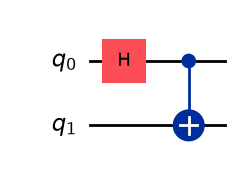

In [9]:
from qiskit import QuantumCircuit
qc = QuantumCircuit(2)

qc.h(0)
qc.cx(0, 1)

qc.draw(output="mpl")

In [11]:
from qiskit.quantum_info import Pauli

ZZ = Pauli('ZZ')
ZI = Pauli('ZI')
IZ = Pauli('IZ')
XX = Pauli('XX')
XI = Pauli('XI')
IX = Pauli('IX')

observables = [ZZ, ZI, IZ, XX, XI, IX]


### Step 2: Optimize the circuit

### Step 3: Execute

In [12]:
from qiskit_aer.primitives import Estimator


In [13]:
estimator = Estimator()

job = estimator.run(circuits=[qc]*len(observables), observables=observables)

job.result().values

array([ 1.        ,  0.02929688,  0.02929688,  1.        , -0.08398438,
       -0.08398438])

### Setp 4: Post Processing and Plotting

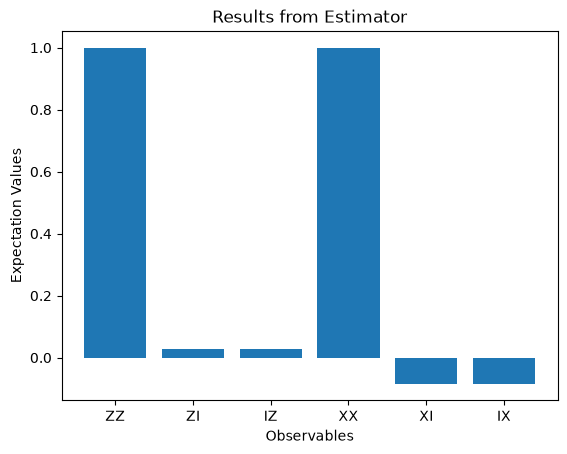

In [14]:
import matplotlib.pyplot as plt

data = ["ZZ", "ZI", "IZ", "XX", "XI", "IX"]
values = job.result().values

plt.bar(data, values)
plt.xlabel("Observables")
plt.ylabel("Expectation Values")
plt.title("Results from Estimator")
plt.show()


## Extend the Hello World example to an n-qubit GHZ state

### Step 1



In [15]:
def get_qc_for_n_qubit_GHZ_state(n):
    qc = QuantumCircuit(n)
    qc.h(0)
    for i in range(n-1):
        qc.cx(0, i + 1)
    return qc

n = 100
qc = get_qc_for_n_qubit_GHZ_state(n)
qc.draw(output="mpl")

In [16]:
from qiskit.quantum_info import SparsePauliOp


operator_strings = ['Z' + 'I'*i +'Z' + 'I' * (n-2-i) for i in range(n-1)]
print(operator_strings)
print(len(operator_strings))
operators = [SparsePauliOp(operator_string) for operator_string in operator_strings]

['ZZIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII', 'ZIZIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII', 'ZIIZIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII', 'ZIIIZIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII', 'ZIIIIZIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII', 'ZIIIIIZIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII', 'ZIIIIIIZIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII', 'ZIIIIIIIZIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII', 'ZIIIIIIIIZIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII', 'ZIIIIIIIIIZIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII

### Step 2: Optimize the problem for quantum execution

In [18]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

# Use the existing backend and transpile the GHZ circuit
pass_manager = generate_preset_pass_manager(optimization_level=1, backend=backend)
qc_transpiled = pass_manager.run(qc)
operators_transpiled_list = [op.apply_layout(qc_transpiled.layout) for op in operators]

In [30]:
# from qiskit_ibm_runtime import QiskitRuntimeService 
# from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
# backend_name = "ibm_kingston"
# backend = QiskitRuntimeService().get_backend(backend_name)
# pass_manager = generate_preset_pass_manager(optimization_level=1, backend=backend)
# qc_transpiled = pass_manager.run(qc)
# operators_transpiled_list = [op.apply_layout(qc_transpiled.layout) for op in operators]

### Step 3: Execute on the backend

In [19]:
from qiskit_ibm_runtime import EstimatorV2 as Estimator
from qiskit_ibm_runtime import EstimatorOptions

options = EstimatorOptions()
options.resilience_level = 1
options.dynamical_decoupling.enable = True
options.dynamical_decoupling.sequence_type = "XY4"

# Keep optimization in transpilation, not here
estimator = Estimator(mode=backend, options=options)

job = estimator.run([(qc_transpiled, operators_transpiled_list)])
print(job.job_id())


C:\Users\hari_\AppData\Local\Temp\ipykernel_10708\3347567300.py:10: DeprecationWarning: The EstimatorV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_estimator.Estimator` provides a new Estimator implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Estimator` import will be updated to point to the client-side estimator in an upcoming release, with the legacy Estimator being available until the deprecation is completed.
  estimator = Estimator(mode=backend, options=options)


db6hjk4vf2bc73d18jv0


### Step 4: Post processing and Plotting

In [20]:
job_id = "db6hjk4vf2bc73d18jv0"
# service = QiskitRuntimeService()
job = service.job(job_id)


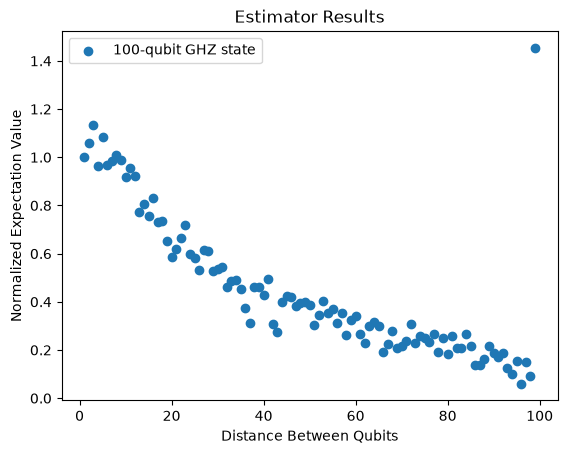

In [21]:
import matplotlib.pyplot as plt

data = list(range(1, len(operators)+1))
result =job.result()[0]
values = result.data.evs 
values = [v / values[0] for v in values]

plt.scatter(data, values, marker='o', label='100-qubit GHZ state')
plt.xlabel("Distance Between Qubits")
plt.ylabel("Normalized Expectation Value")
plt.title("Estimator Results")
plt.legend()
plt.show()

# Episode 4: Primitive

### Transvere Field Ising Mode

In [45]:
from qiskit import QuantumCircuit
from qiskit.circuit.library import YGate, UnitaryGate
import numpy as np

SYGate = UnitaryGate (YGate().power(1/2), label=r"$\sqrt{Y}$")
SYdgGate = UnitaryGate (SYGate.inverse(), label=r"$\sqrt{Y}^\dag$")

def generate_1d_tfim_circuit(num_qubits, num_trotter_steps, rx_angle, num_cl_bits=0, trotter_barrer=False, layer_barrier=False): 
    if num_cl_bits > 0:
        qc = QuantumCircuit(num_qubits, num_cl_bits)
    else:
        qc = QuantumCircuit(num_qubits)
        
    for trotter_step in range(num_trotter_steps):
        add_1d_tfim_trotter_layer(qc, rx_angle, layer_barrier=layer_barrier)
        if trotter_barrer:
            qc.barrier()
    return qc

def add_1d_tfim_trotter_layer(qc, rx_angle, layer_barrier=False):
    # Adding Rzz in the even layers
    for i in range(0, qc.num_qubits-1, 2):
        qc.sdg([i, i+1])
        qc.append(SYGate, [1+1])
        qc.cx(1, 1+1)
        qc.append(SYdgGate, [i+1])
    if layer_barrier:
        qc.barrier()
    #Adding Rzz in the even layers
    for i in range(1, qc.num_qubits-1, 2):
        qc.sdg([i, i+1])
        qc.append(SYGate, [i+1])
        qc.cx(i, 1+1)
        qc.append(SYdgGate, [i+1])
    if layer_barrier:
        qc.barrier()

    qc.rx(rx_angle, list(range(qc.num_qubits)))
    if layer_barrier:
        qc.barrier()

In [46]:
num_qubits=100
num_trotter_steps = 1
rx_angle = 0.5 * np.pi
qc = generate_1d_tfim_circuit(num_qubits, num_trotter_steps, rx_angle,trotter_barrer=True, layer_barrier=True)

qc.draw(output='mpl', fold=-1)

## Demo Sampler

In [47]:
def append_mirrored_1d_tfim_circuit(qc, num_qubits, num_trotter_steps, rx_angle, trotter_barriers = False, layer_barriers = False):
    for trotter_step in range(num_trotter_steps):
        add_mirrored_1d_tfim_trotter_layer(qc, rx_angle, layer_barriers)
        if trotter_barriers:
            qc.barrier()

def add_mirrored_1d_tfim_trotter_layer(qc, rx_angle, layer_barriers = False):
    qc.rx(-rx_angle, list(range(qc.num_qubits)))
    if layer_barriers:
        qc.barrier()
    #Adding Rzz in the odd layers
    for i in range(1, qc.num_qubits-1, 2):
        qc.append(SYGate, [i+1])
        qc.cx(i, i+1)
        qc.append(SYdgGate, [i+1])
        qc.s([i, i+1])
    if layer_barriers:
        qc.barrier()
    #Adding Rzz in the odd layers
    for i in range(0, qc.num_qubits-1, 2):
        qc.append(SYGate, [i+1])
        qc.cx(1, 1+1)
        qc.append(SYdgGate, [i+1])
        qc.s([i, i+1])
    if layer_barriers:
        qc.barrier()

In [48]:
append_mirrored_1d_tfim_circuit(qc, num_qubits, num_trotter_steps, rx_angle, trotter_barriers=True, layer_barriers=True)
qc.draw(output='mpl', fold=-1)

### Step 1: Map the problem to circuits and observables

In [50]:
# Fix the TFIM helper functions first (if not already fixed elsewhere)
def generate_1d_tfim_circuit(
    num_qubits,
    num_trotter_steps,
    rx_angle,
    num_cl_bits=0,
    trotter_barriers=False,
    layer_barriers=False,
):
    if num_cl_bits > 0:
        qc = QuantumCircuit(num_qubits, num_cl_bits)
    else:
        qc = QuantumCircuit(num_qubits)

    for _ in range(num_trotter_steps):
        add_1d_tfim_trotter_layer(qc, rx_angle, layer_barriers=layer_barriers)
        if trotter_barriers:
            qc.barrier()
    return qc


def add_1d_tfim_trotter_layer(qc, rx_angle, layer_barriers=False):
    # even bonds
    for i in range(0, qc.num_qubits - 1, 2):
        qc.sdg([i, i + 1])
        qc.append(SYGate, [i])
        qc.cx(i, i + 1)
        qc.append(SYdgGate, [i + 1])

    if layer_barriers:
        qc.barrier()

    # odd bonds
    for i in range(1, qc.num_qubits - 1, 2):
        qc.sdg([i, i + 1])
        qc.append(SYGate, [i])
        qc.cx(i, i + 1)
        qc.append(SYdgGate, [i + 1])

    if layer_barriers:
        qc.barrier()

    qc.rx(rx_angle, list(range(qc.num_qubits)))

    if layer_barriers:
        qc.barrier()


def append_mirrored_1d_tfim_circuit(
    qc,
    num_qubits,
    num_trotter_steps,
    rx_angle,
    trotter_barriers=False,
    layer_barriers=False,
):
    for _ in range(num_trotter_steps):
        add_mirrored_1d_tfim_trotter_layer(qc, rx_angle, layer_barriers=layer_barriers)
        if trotter_barriers:
            qc.barrier()


def add_mirrored_1d_tfim_trotter_layer(qc, rx_angle, layer_barriers=False):
    qc.rx(-rx_angle, list(range(qc.num_qubits)))

    if layer_barriers:
        qc.barrier()

    # odd bonds
    for i in range(1, qc.num_qubits - 1, 2):
        qc.append(SYGate, [i])
        qc.cx(i, i + 1)
        qc.append(SYdgGate, [i + 1])
        qc.s([i, i + 1])

    if layer_barriers:
        qc.barrier()

    # even bonds
    for i in range(0, qc.num_qubits - 1, 2):
        qc.append(SYGate, [i])
        qc.cx(i, i + 1)
        qc.append(SYdgGate, [i + 1])
        qc.s([i, i + 1])

    if layer_barriers:
        qc.barrier()

In [51]:
# Fixed sampler cell
max_trotter_steps = 10
num_qubits = 100
measured_qubits = [49, 50]
qc_list = []

for trotter_step in range(1, max_trotter_steps + 1):
    qc = generate_1d_tfim_circuit(
        num_qubits,
        trotter_step,
        rx_angle,
        num_cl_bits=len(measured_qubits),
        trotter_barriers=True,
        layer_barriers=True,
    )
    append_mirrored_1d_tfim_circuit(
        qc,
        num_qubits,
        trotter_step,
        rx_angle,
        trotter_barriers=True,
        layer_barriers=True,
    )
    qc.measure(measured_qubits, list(range(len(measured_qubits))))
    qc_list.append(qc)

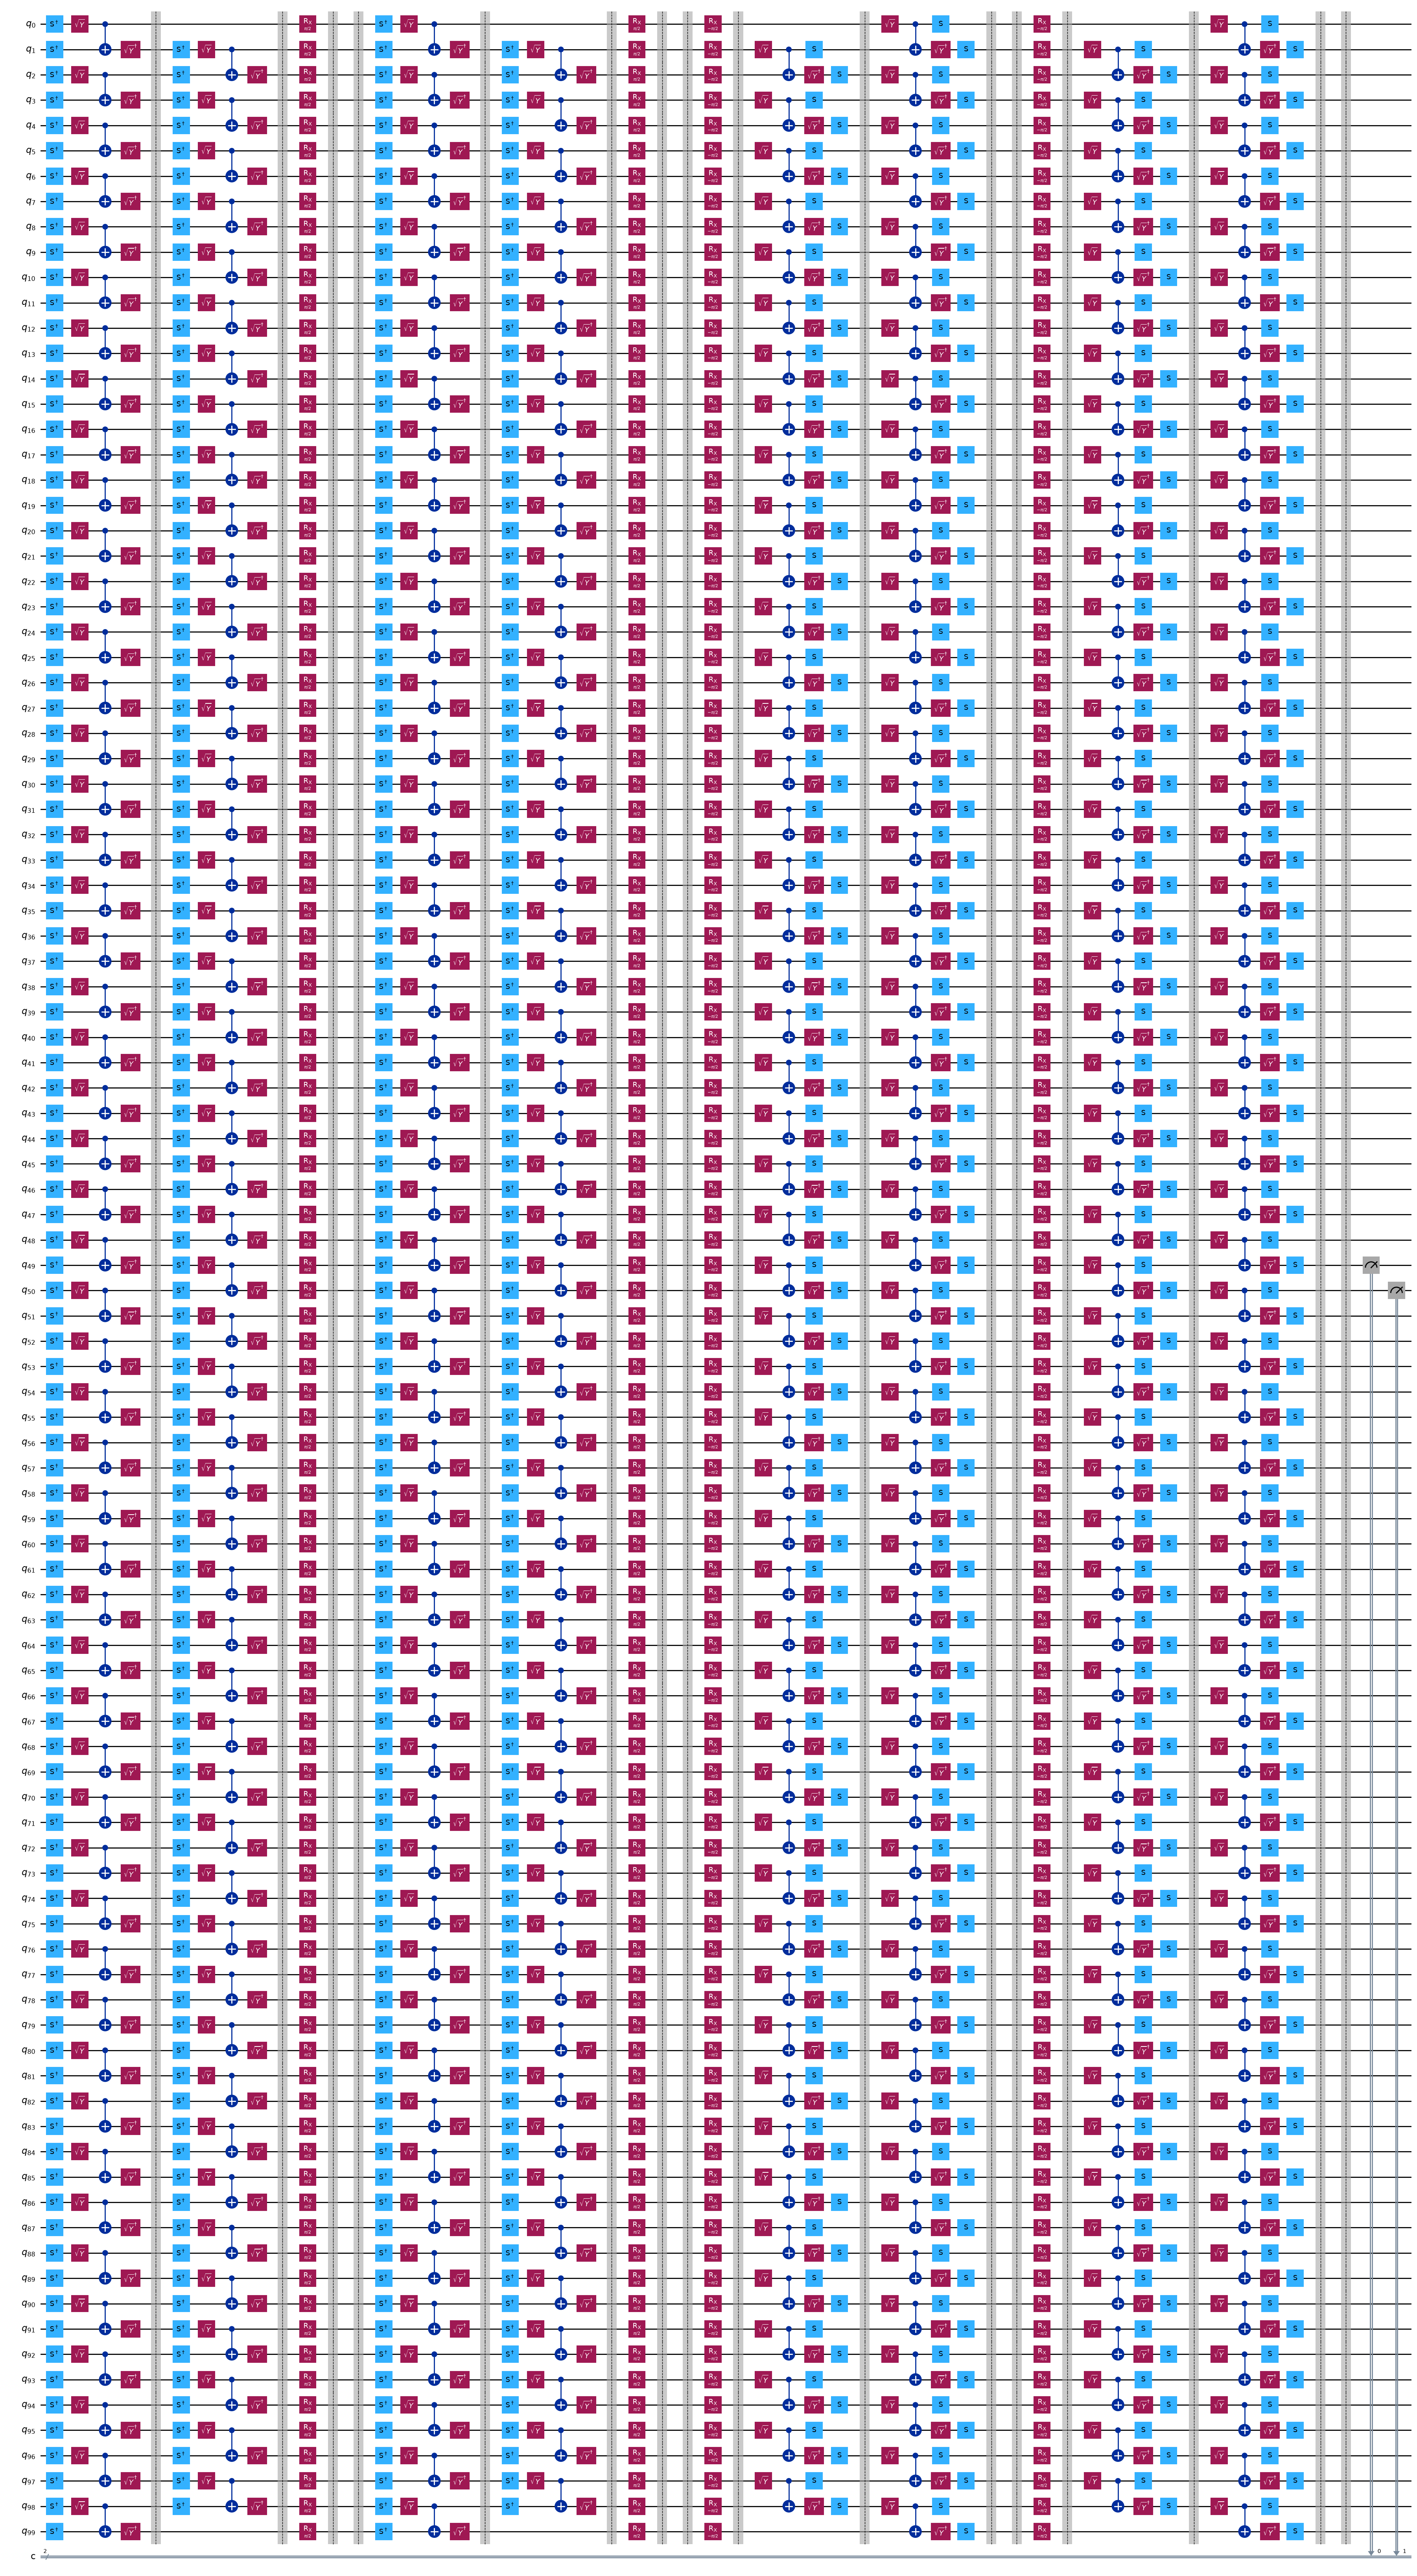

In [52]:
qc_list[1].draw(output="mpl", fold=-1)

### Step 2: Optimize

In [29]:
from qiskit import transpile

backend_name = "ibm_kingston"

# If backend is not already defined in the notebook, fetch it this way
backend = service.backend(name=backend_name)

print("Done getting the backend")
qc_transpiled_list = transpile(qc_list, backend=backend, optimization_level=1)

qiskit_runtime_service.backends:WARNING:2026-10-12 23:14:02,247: Using instance: open-instance, plan: open


Done getting the backend


### Step 3: Execute on Hardware

In [30]:
from qiskit_ibm_runtime import SamplerV2 as Sampler

sampler = Sampler(mode=backend)
sampler.options.dynamical_decoupling.enable = True
sampler.options.dynamical_decoupling.sequence_type = "XY4"

job = sampler.run(qc_transpiled_list)
print(job.job_id())

C:\Users\hari_\AppData\Local\Temp\ipykernel_10708\3282935157.py:3: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(mode=backend)


db6hos4lf4us73c5d9t0


### Step 4: Post Processing and Plotting

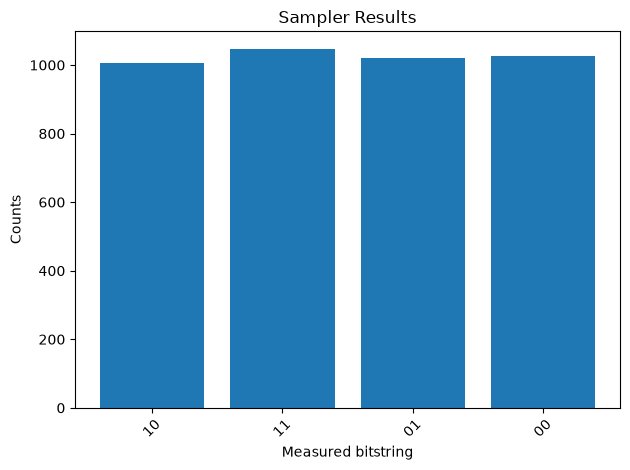

In [33]:
job_id = "db6hos4lf4us73c5d9t0"
job = service.job(job_id)

# Sampler V2: PrimitiveResult -> one SamplerPubResult per input circuit (PUB)
sampler_result = job.result()
pub = sampler_result[0]  # change index to match the trotter step you want
creg_name = next(iter(pub.data.keys()))  # usually "c" or "meas"
counts = pub.data[creg_name].get_counts()

labels = list(counts.keys())
values = list(counts.values())

plt.bar(labels, values)
plt.xlabel("Measured bitstring")
plt.ylabel("Counts")
plt.title("Sampler Results")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [34]:
job_id = "db6hos4lf4us73c5d9t0"
job =service.job(job_id)
survival_probability_list = []
for trotter_step in range(max_trotter_steps):
    try:
        data = job.result() [trotter_step].data
        survival_probability_list.append(data.c.get_counts() ['0' * len (measured_qubits)] / data.c.num_shots)
    except:
        survival_probability_list.append(0)

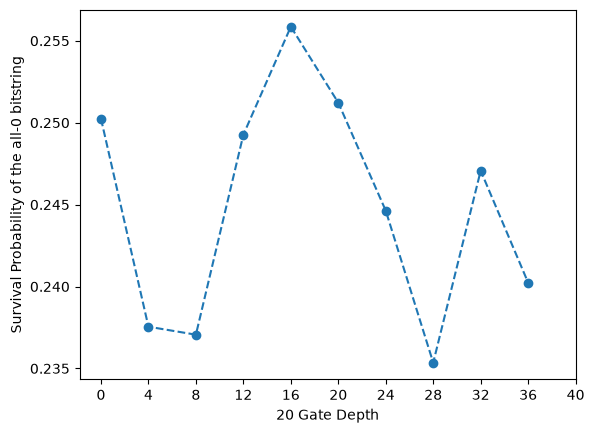

In [35]:
import matplotlib.pyplot as plt
plt.plot(list(range(0, 4 * max_trotter_steps, 4)), survival_probability_list, '--o')
plt.xlabel('20 Gate Depth')
plt.ylabel('Survival Probability of the all-0 bitstring')
plt.xticks(np.arange(0, 44, 4))
plt.show()

## Estimator

### Step 1: Mapping the Problem

In [53]:
from qiskit.circuit import Parameter
rx_angle = Parameter("rx_angle")
trotter_steps = 2
qc = generate_1d_tfim_circuit(num_qubits, trotter_steps, rx_angle)
from qiskit.quantum_info import SparsePauliOp
n_logical = qc.num_qubits
middle_index = n_logical // 2
observable = SparsePauliOp(
    "I" * middle_index + "Z" + "I" * (n_logical - middle_index - 1)
)

### Step 2: Optimize the circuit

In [54]:
from qiskit import transpile
from qiskit.quantum_info import SparsePauliOp

backend_name = "ibm_kingston"
backend = service.backend(name=backend_name)
qc_transpiled = transpile(qc, backend=backend, optimization_level=1)

n_logical = qc.num_qubits
middle_index = n_logical // 2
observable = SparsePauliOp(
    "I" * middle_index + "Z" + "I" * (n_logical - middle_index - 1)
)
observable = observable.apply_layout(qc_transpiled.layout)


qiskit_runtime_service.backends:WARNING:2026-10-12 23:44:16,661: Using instance: open-instance, plan: open


### Step 3: Execute of Quantum Hardware

In [55]:
# Prerequisites: Estimator Step 1 (qc) and Step 2 (qc_transpiled, backend).
from qiskit_ibm_runtime import EstimatorV2, EstimatorOptions
from qiskit.quantum_info import SparsePauliOp
import numpy as np

min_rx_angle = 0
max_rx_angle = np.pi / 2
num_rx_angle = 12
rx_angle_list = np.linspace(min_rx_angle, max_rx_angle, num_rx_angle)

from qiskit import transpile

n_logical = qc.num_qubits
needs_transpile = (
    "qc_transpiled" not in globals()
    or qc_transpiled.layout is None
    or len(qc_transpiled.layout.final_index_layout()) != n_logical
)
if needs_transpile:
    backend_name = "ibm_kingston"
    backend = service.backend(name=backend_name)
    qc_transpiled = transpile(qc, backend=backend, optimization_level=1)

middle_index = n_logical // 2
observable = SparsePauliOp(
    "I" * middle_index + "Z" + "I" * (n_logical - middle_index - 1)
)
observable = observable.apply_layout(qc_transpiled.layout)

options = EstimatorOptions()
options.resilience_level = 1
options.dynamical_decoupling.enable = True
options.dynamical_decoupling.sequence_type = "XY4"
estimator = EstimatorV2(mode=backend, options=options)
job = estimator.run([(qc_transpiled, observable, rx_angle_list)])
print(job.job_id())

C:\Users\hari_\AppData\Local\Temp\ipykernel_10708\1283276178.py:34: DeprecationWarning: The EstimatorV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_estimator.Estimator` provides a new Estimator implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Estimator` import will be updated to point to the client-side estimator in an upcoming release, with the legacy Estimator being available until the deprecation is completed.
  estimator = EstimatorV2(mode=backend, options=options)


db6i704lf4us73c5e13g


### Post Processing and Plotting

(-0.1, 1.1)

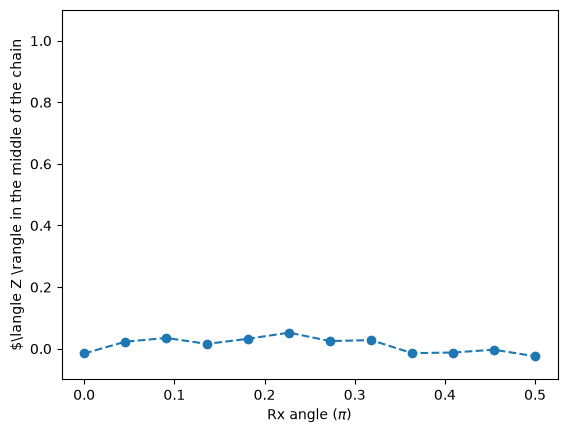

In [56]:
job_id = "db6i704lf4us73c5e13g"
job = service.job(job_id)
exp_val_list = job.result()[0].data.evs
plt.plot(rx_angle_list/np.pi, exp_val_list, '--o')
plt.xlabel(r'Rx angle ($\pi$)')
plt.ylabel(r'$\langle Z \rangle in the middle of the chain')
plt.ylim(-0.1, 1.1)

# Episode 5: Dynamic Circuits

### Long-range CNOT gate teleportation using dynamic circuits
#### Step 1: Map the problem to circuits and operators

In [3]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.circuit.classical import expr

def check_even(n: int) -> int:
    return 1 if n % 2 == 0 else 2

def get_dynamic_CNOT_circuit(num_qubit):
    """
    Long-range CNOT on a linear chain (IBM LRCX / dynamic-circuit tutorial).
    Qubit 0 = control (|+>), qubit num_qubit-1 = target.
    """
    n = num_qubit - 2
    k = int(n / 2)
    control = 0
    target = num_qubit - 1

    qr = QuantumRegister(num_qubit)
    classical_regs = [ClassicalRegister(2, name="cr3")]
    if n > 1:
        classical_regs.append(ClassicalRegister(k, name="cr1"))
    if n > 0:
        classical_regs.append(ClassicalRegister(n - k, name="cr2"))

    qc = QuantumCircuit(qr, *classical_regs)
    qc.h(control)
    qc.barrier()

    x0 = check_even(n)
    if n % 2 != 0:
        qc.cx(control, 1)

    for i in range(k):
        qc.h(x0 + 2 * i)
        qc.cx(x0 + 2 * i, x0 + 2 * i + 1)

    for i in range(k + 1):
        qc.cx(x0 - 1 + 2 * i, x0 + 2 * i)

    for i in range(1, k + x0):
        qc.h(2 * i + 1 - x0)

    qc.barrier()

    if n > 1:
        _, c1, c2 = qc.cregs
        for i in range(k):
            qc.measure(2 * i + x0, c1[i])
    elif n > 0:
        _, c2 = qc.cregs

    if n > 0:
        for i in range(1, k + x0):
            qc.measure(2 * i + 1 - x0, c2[i - 1])

    if n > 1:
        parity_ZZ = None
        for i in range(k):
            if i == 0:
                parity_ZZ = expr.lift(c1[i])
            else:
                parity_ZZ = expr.bit_xor(c1[i], parity_ZZ)

    if n > 0:
        parity_XX = None
        for i in range(1, k + x0):
            if i == 1:
                parity_XX = expr.lift(c2[i - 1])
            else:
                parity_XX = expr.bit_xor(c2[i - 1], parity_XX)

    if n > 0:
        with qc.if_test(parity_XX):
            qc.z(control)
    if n > 1:
        with qc.if_test(parity_ZZ):
            qc.x(target)

    return qc

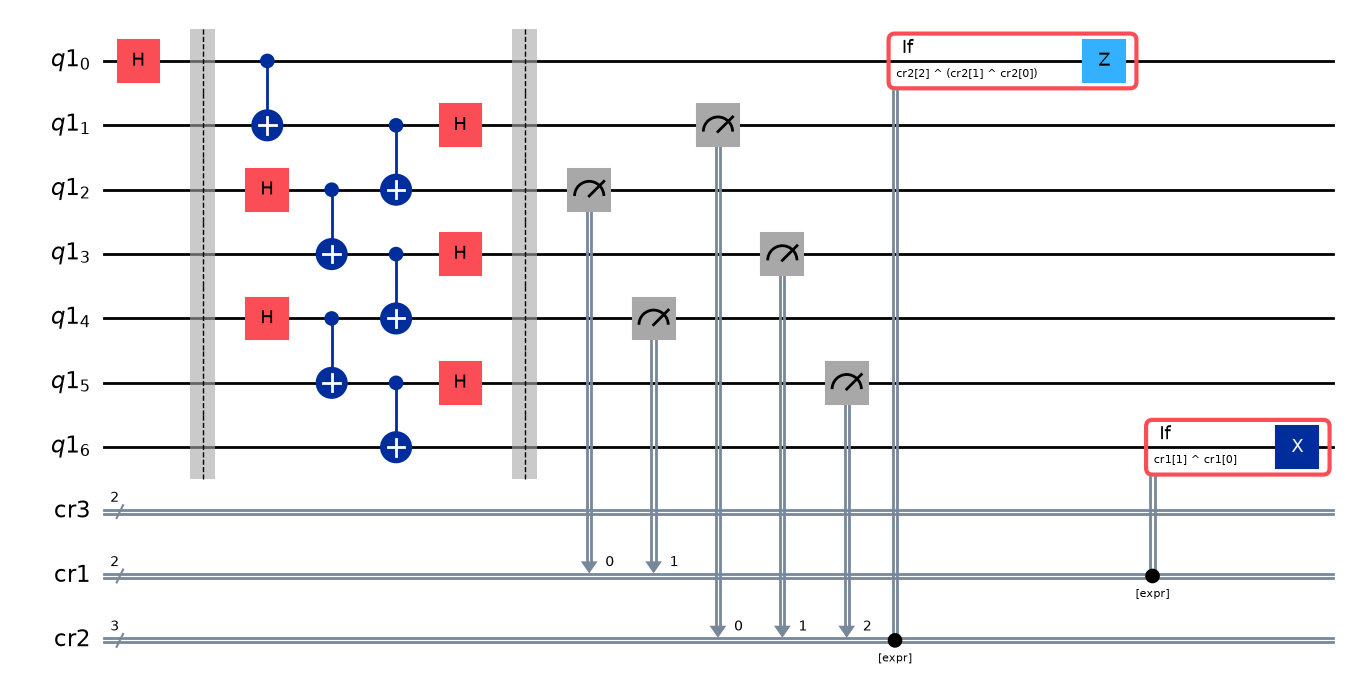

In [4]:
qc = get_dynamic_CNOT_circuit(num_qubit=7)
qc.draw(output='mpl')

In [5]:
max_num_qubit = 41
qc_list = []
num_qubit_list = list(range(7, max_num_qubit+1, 2))
for num_qubit in num_qubit_list:
    qc_list.append(get_dynamic_CNOT_circuit(num_qubit))

#### Step 2: Optimize the problem for quantum execution


In [8]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

backend_name = "ibm_kingston"
if "service" not in globals():
    from qiskit_ibm_runtime import QiskitRuntimeService
    service = QiskitRuntimeService(channel="ibm_cloud", token=QUANTUM_IBM_API_KEY)
backend = service.backend(name=backend_name)
pm = generate_preset_pass_manager(optimization_level=1, backend=backend)
qc_transpiled_list = pm.run(qc_list)

qiskit_runtime_service.backends:WARNING:2026-10-13 21:36:53,222: Using instance: open-instance, plan: open


#### Step 3: Execute the circuit

In [9]:
from qiskit_ibm_runtime import SamplerV2 as Sampler

sampler = Sampler(mode=backend)
sampler.options.dynamical_decoupling.enable = True
sampler.options.dynamical_decoupling.sequence_type = "XY4"

job = sampler.run(qc_transpiled_list)
print(job.job_id())

TypeError: SamplerV2.__init__() got an unexpected keyword argument 'backend'